# Dynesty series: the retrievals against the noiseless predictions

`plot_dynesty.ipynb` shows one stored run in detail. This notebook reads **every** stored run and compares it with what the noiseless analysis predicts for it (`dynesty_utils.run_prediction`, theory in `Bias Analysis/Evidence_Prediction.ipynb`):

- the Bayes factor between the extended-source and the point-source model, $\ln B \approx \chi^2_{\min}/2 + \zeta\sqrt{\chi^2_{\min}}$, with $\chi^2_{\min}$ and the whitened residual $r_\perp$ from the noiseless $A_B$-only fit at the truth's own resolution and $\zeta = \hat r_\perp\cdot z$. In a simulation the standardised noise $z = (y_{\rm obs} - y_{\rm true})/\sigma$ is known exactly, so every run has its own prediction, without sampling;
- the posterior-median difference of $A_B$ between the two models on the same data, against the noiseless bias $\Delta A_B$;
- the posterior width of $A_B$ under the point-source model, against the Fisher $\sigma_{A_B}$;
- for the point-source model with redistribution, the significance of the spurious $F$ in each realisation, $z_F = \sqrt{2\,\Delta\ln\mathcal{L}_{\max}}$ between the best fits with and without $F$, against $\max(z_F^{\rm noiseless} + \zeta_F,\,0)$, where $\zeta_F$ is the noise projected on the part of the $A_B$-only residual that $F$ absorbs (`series_table(..., redist=True)`).

The runs are grouped in `SERIES` (one pfrac per series; a run still in the queue is listed as missing and skipped, so re-run the notebook as the queue finishes). The retrievals of the paper are one series per planet and primary mode (`PAPER_SERIES`: baseline settings, pfrac 0.8, the same seeds for every planet); section 7 collects them for Sec. 4.4 of the paper. Runs whose difference from the baseline is not in the file name sit in subfolders of `dynesty_results/` (`null_test/`: point-source truth; `free_geometry/`: $a/R_\star$ and $R_p/R_\star$ sampled) and carry `subfolder=` in their entry; `series_table` checks each against its pickles.

The prediction applies to extended source vs point source only (equal parameter counts). Bayes factors against the point-source model with redistribution contain the Occam term of the $F$ prior and are tabulated as measured (section 5). Section 6 compares the special runs (three detectors, free geometry, null test, $A_B = 0.05$, 2 orbits) with their own predictions, and section 7 summarises the paper's retrievals per planet and mode, shows the noise realisations of the reference planets one by one, and checks how representative their seeds are.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from IPython.display import display
from dynesty_utils import *
from simple_bias_analysis import fit_truth, evidence_probability   # the noiseless fits of the bias analysis, for the special runs of section 6; P(ln B > x) of the linear prediction, for section 7
from HItargets_utils import PAPER_PLANETS, JWST_BANDS, detector_label, A_B_BOUNDS, A_B_FIT_BOUNDS
from paper_plot_utils import paper_figure, paper_theme

RESULTS_DIR = "dynesty_results"   # where run_dynesty.py saves; subfolders null_test/ and free_geometry/
N_JOBS = -1                       # the noiseless references and the rows run process-parallel (loky)
K_JITTER = 200                    # jittered realisations for the sampler error of ln B (0: analytic errors only)

In [2]:
# The series, as the keywords of find_dataset (planet, instrument, the settings that deviate from the baseline: seed 42, pfrac 0.8, A_B, n_bins, n_orbits of HItargets_utils).
JOINT, LRS = "JWST_NIRSpec.G395H_joint", "MIRI/LRS"
NRS1, NRS2 = JWST_BANDS[:2]
IMAGING = ("MIRI/F1280W", "MIRI/F1500W", "MIRI/F1800W")
THREE = (NRS1, NRS2, LRS)                      # one joint fit of the three detectors
T, K = "TOI-2431 b", "K2-141 b"

PAPER_SEEDS = {p: range(40, 50) if p in (T, K) else range(40, 44) for p in PAPER_PLANETS}   # noise realisations of the paper's retrievals: ten for the reference planets, four for the others
PAPER_SERIES = {f"{p}, {lab}": [dict(planet=p, instrument=ins, seed=s) for s in PAPER_SEEDS[p]] for p in PAPER_PLANETS for ins, lab in ((JOINT, "joint NIRSpec"), (LRS, "MIRI/LRS"))}

SERIES = {
    # --- the paper's retrievals: every paper planet in the two primary modes at the baseline settings, pfrac 0.8 (section 7) -----------
    **PAPER_SERIES,
    # --- seed 42: the single bands of the reference planets -------------------------------------------------------------------------
    "seed 42, single bands":        [dict(planet=T, instrument=ins) for ins in (NRS1, NRS2, *IMAGING)] + [dict(planet=K, instrument=ins) for ins in (NRS1, NRS2)],
    # --- TOI-2431 b, one setting changed at a time --------------------------------------------------------------------------------
    "TOI-2431 b, n_orbits 3 / 10":  [dict(planet=T, instrument=ins, n_orbits=n, **kw) for ins in (JOINT, LRS) for n, kw in ((3, {}), (10, {}), (10, dict(seed=43)))],
    "TOI-2431 b, n_bins 20 / 36":   [dict(planet=T, instrument=ins, n_bins=n) for ins in (JOINT, LRS) for n in (20, 36)],
    "TOI-2431 b, A_B = 0.4":        [dict(planet=T, instrument=ins, A_B=0.4) for ins in (JOINT, LRS)],
    # --- special runs --------------------------------------------------------------------------------------------------------------
    "three detectors":              [dict(planet=p, instrument=THREE, seed=43) for p in (T, K)],
    "free geometry":                [dict(planet=p, instrument=ins, seed=s, subfolder="free_geometry") for p in (T, K) for ins in (JOINT, LRS) for s in (40, 41, 43)],
    "null test":                    [dict(planet=T, instrument=ins, seed=s, subfolder="null_test") for ins in (JOINT, LRS) for s in (43, 44, 45)],
    "TOI-2431 b, A_B = 0.05":       [dict(planet=T, instrument=ins, A_B=0.05, seed=43) for ins in (JOINT, LRS)],
    "TOI-2431 b LRS, 2 orbits":     [dict(planet=T, instrument=LRS, n_orbits=2, seed=s) for s in range(43, 48)],
    # --- the same data at another pfrac: NOT part of the paper's series, only of the per-run checks and the pfrac comparison ------------
    "TOI-2431 b joint (pfrac 0)":   [dict(planet=T, instrument=JOINT, seed=s, pfrac=0) for s in range(40, 50)],
    "TOI-2431 b joint (pfrac 1)":   [dict(planet=T, instrument=JOINT, seed=s, pfrac=1) for s in range(43, 47)],
    "TOI-2431 b LRS (other pfrac)": [dict(planet=T, instrument=LRS, seed=s, pfrac=p) for s, p in ((43, 0), (44, 0), (45, 1), (46, 1))],
}

# every stored run should be in a series: the stems on disk that no entry names
ALL = {f"{name} | {k}": kw for name, entries in SERIES.items() for k, kw in enumerate(entries)}
have = list_datasets(RESULTS_DIR)
on_disk = {os.path.join(sub, tag) if sub else tag for sub, tag in zip(have.subfolder, have.tag)}
listed = set()
for kw in ALL.values():
    try: listed.add(find_dataset(RESULTS_DIR, **kw))
    except FileNotFoundError: pass
print(f"{len(on_disk)} datasets in {RESULTS_DIR}/ (with subfolders), {len(listed)} of them in a series")
for stem in sorted(on_disk - listed): print(f"   run not in any series: {stem}")

149 datasets in dynesty_results/ (with subfolders), 149 of them in a series


## 1. The table: one row per run

`series_table` regenerates each configuration's noiseless truth once (the runs of one planet, mode and setting that differ only in seed and pfrac share it), fits the misspecified model to it at the truth's resolution (with `redist=True` also the point-source model with redistribution, jointly in $A_B$ and $F$), and evaluates every run against it. Each row asserts that $z$ reproduces the draws of `default_rng(seed)`, which also checks the regenerated truth; `z_dev` is the largest deviation. Missing and incomplete runs are listed below.

In [3]:
tab, missing = series_table(RESULTS_DIR, SERIES, K=K_JITTER, n_jobs=N_JOBS, redist=True)
tab["mode"] = tab["instrument"].map(lambda ins: {JOINT: "joint NIRSpec", "joint-NRS1+NRS2+LRS": "NIRSpec + LRS", LRS: "MIRI/LRS"}.get(ins, detector_label(ins)))   # short labels: NRS1, NRS2, F1280W, ...
runs = tab.drop_duplicates("stem")   # a run named by two series would count twice: every statistic over ALL runs uses each once

print(f"{len(runs)} runs evaluated ({len(tab)} series rows), {len(missing)} missing or incomplete:")
miss = pd.DataFrame([dict(series=name, **{k: (v if isinstance(v, (str, int, float)) else "+".join(x.split("_")[-1].split("/")[-1] for x in v)) for k, v in kw.items()}, reason=why) for name, kw, why in missing])
if len(miss): print(miss.fillna("").to_string(index=False))
stale = runs[runs["grid_change"] > 1e-6]
if len(stale): print(f"\nSTALE pickles (stellar grid changed since the run): {', '.join(stale['stem'])}")

148 runs evaluated (148 series rows), 12 missing or incomplete:
       series     planet               instrument  seed     subfolder                      reason
free geometry TOI-2431 b JWST_NIRSpec.G395H_joint    40 free_geometry                      no run
free geometry TOI-2431 b JWST_NIRSpec.G395H_joint    41 free_geometry                      no run
free geometry TOI-2431 b JWST_NIRSpec.G395H_joint    43 free_geometry                      no run
free geometry TOI-2431 b                 MIRI/LRS    40 free_geometry                      no run
free geometry TOI-2431 b                 MIRI/LRS    41 free_geometry                      no run
free geometry TOI-2431 b                 MIRI/LRS    43 free_geometry                      no run
free geometry   K2-141 b JWST_NIRSpec.G395H_joint    40 free_geometry incomplete: only hyperillum
free geometry   K2-141 b JWST_NIRSpec.G395H_joint    41 free_geometry                      no run
free geometry   K2-141 b JWST_NIRSpec.G395H_joint    4

## 2. Validation: $\zeta$ from the noise against $\zeta$ from the sampler

Two independent routes to the same number. $\zeta$ is the dot product $\hat r_\perp\cdot z$ of the noiseless residual with the simulated noise. $\zeta_{\rm inferred} = (2\,\Delta\ln\mathcal{L}_{\max} - \chi^2_{\min})/(2\sqrt{\chi^2_{\min}})$ uses only the sampler's best likelihoods; the table shows their difference. They agree where the linearisation holds and both models absorb the same directions; the sampler's finite resolution of $\ln\mathcal{L}_{\max}$ and the prior edge $A_B \geq 0$ (low-signal planets, $A_B = 0.05$) are the expected exceptions. `ΔH` is the difference in information between the two models: the Bayes factor follows the likelihood ratio only while it is small. `χ²_min / floor` is $\chi^2_{\min}$ over the numerical floor (the truth's own model at the injected parameters on the likelihood's grid against the truth curve) and must be large. `setting` names what a run changes from the baseline; `ln B` carries the sampler error from the jittered realisations.

What to look for: `ζ − ζ_inferred` small against the unit scatter of $\zeta$, for every run; the runs with the largest deviation are listed first. The last line does the same for the fit with redistribution: the significance of $F$ in each realisation against $\max(z_F + \zeta_F, 0)$, over the runs with a hyperillumination truth and fixed geometry. The lines below the table give the maxima and rms over the baseline-type runs and the largest deviation of the regenerated noise from `default_rng(seed)` (`z_dev`).

In [4]:
from HItargets_utils import DEFAULT_A_B, DEFAULT_N_BINS, DEFAULT_N_ORBITS

# Table helpers for sections 2 and 3: `setting` names what a run changes from the baseline of HItargets_utils (kind of run, A_B, n_bins, n_orbits) in one column instead of four
setting = lambda r: ", ".join(s for s, on in ((str(r["kind"]).replace("_", " "), r["kind"] != ""), (f"A_B = {r['A_B_true']:g}", r["A_B_true"] != DEFAULT_A_B),
                                                (f"{r['n_bins']:g} bins", r["n_bins"] != DEFAULT_N_BINS), (f"{r['n_orbits']:g} orbits", r["n_orbits"] != DEFAULT_N_ORBITS)) if on) or "baseline"
fmt = lambda f: (lambda v: "-" if pd.isna(v) else f.format(v))
pm = lambda m, s, f: "-" if pd.isna(m) else f.format(m) + ("" if pd.isna(s) else " ± " + f.format(s))   # value ± error (or ± sd), the ± only where defined

chk = runs.assign(dzeta=runs["zeta"] - runs["zeta_inferred"], dlnB=runs["lnB"] - runs["lnB_pred"])
chk = chk.reindex(chk["dzeta"].abs().sort_values(ascending=False).index)   # largest deviation first
display(pd.DataFrame({"planet": chk["planet"], "mode": chk["mode"], "setting": chk.apply(setting, axis=1), "seed": chk["seed"], "pfrac": chk["pfrac"].map(fmt("{:g}")),
                      "χ²_min": chk["chi2_min"].map(fmt("{:.2f}")), "χ²_min / floor": (chk["chi2_min"] / chk["chi2_floor"]).map(fmt("{:.0f}")),
                      "ζ": chk["zeta"].map(fmt("{:+.2f}")), "ζ − ζ_inferred": chk["dzeta"].map(fmt("{:+.3f}")), "prediction": chk["lnB_pred"].map(fmt("{:.2f}")),
                      "ln B": [pm(v, e, "{:.2f}") for v, e in zip(chk["lnB"], chk["lnB_err_jitter"])], "ln B − prediction": chk["dlnB"].map(fmt("{:+.2f}")),
                      "ΔH": chk["dH"].map(fmt("{:+.2f}"))}).style.hide(axis="index"))
base = chk[(chk["kind"] == "") & (chk["A_B_true"] >= 0.2)]
print(f"\nbaseline-type runs (hyperillumination truth, fixed geometry, A_B >= 0.2): max |zeta - zeta_inferred| = {base['dzeta'].abs().max():.3f}, rms {np.sqrt(np.mean(base['dzeta'] ** 2)):.3f};  "
      f"max |ln B - prediction| = {base['dlnB'].abs().max():.2f}, rms {np.sqrt(np.mean(base['dlnB'] ** 2)):.2f};  max |dH| = {base['dH'].abs().max():.2f};  max z_dev = {runs['z_dev'].max():.1e}")
print(f"chi2_min / chi2_floor >= {np.nanmin(runs['chi2_min'] / runs['chi2_floor']):.0f} in every run")
dzF = (base["zF_obs"] - base["zF_pred"]).dropna()
print(f"fit with redistribution, the same runs ({len(dzF)}): z_F - max(z_F,noiseless + zeta_F, 0): max |.| = {dzF.abs().max():.2f}, rms {np.sqrt(np.mean(dzF ** 2)):.2f};  corr = {np.corrcoef(base.loc[dzF.index, 'zF_obs'], base.loc[dzF.index, 'zF_pred'])[0, 1]:.3f}")

planet,mode,setting,seed,pfrac,χ²_min,χ²_min / floor,ζ,ζ − ζ_inferred,prediction,ln B,ln B − prediction,ΔH
TOI-2431 b,MIRI/LRS,A_B = 0.05,43,0.8,15.03,15430,-0.29,-0.283,6.37,8.04 ± 0.13,+1.67,-0.34
K2-141 b,MIRI/LRS,baseline,49,0.8,4.13,7841,-1.81,-0.251,-1.61,-1.12 ± 0.11,+0.49,+0.03
TOI-2431 b,MIRI/LRS,baseline,49,0.8,12.69,14933,-1.82,-0.159,-0.13,0.44 ± 0.12,+0.57,+0.01
Kepler-78 b,MIRI/LRS,baseline,40,0.8,0.16,4224,+1.14,-0.132,0.54,0.69 ± 0.09,+0.15,-0.08
K2-131 b,MIRI/LRS,baseline,40,0.8,0.37,6539,+1.09,-0.096,0.85,1.05 ± 0.09,+0.20,-0.07
K2-141 b,joint NIRSpec,baseline,49,0.8,5.18,3878,-1.21,-0.080,-0.16,0.03 ± 0.17,+0.19,+0.04
TOI-1798.02,MIRI/LRS,baseline,40,0.8,0.34,1568,+1.14,-0.078,0.84,1.08 ± 0.10,+0.24,-0.16
TOI-1444 b,MIRI/LRS,baseline,40,0.8,0.40,2571,+1.10,-0.070,0.90,1.02 ± 0.10,+0.13,-0.04
TOI-2431 b,F1800W,baseline,42,0.8,0.92,26192,-1.20,-0.062,-0.70,-0.57 ± 0.05,+0.13,-0.12
K2-131 b,MIRI/LRS,baseline,43,0.8,0.37,6539,-0.39,-0.059,-0.05,0.22 ± 0.09,+0.28,-0.17



baseline-type runs (hyperillumination truth, fixed geometry, A_B >= 0.2): max |zeta - zeta_inferred| = 0.251, rms 0.039;  max |ln B - prediction| = 0.57, rms 0.17;  max |dH| = 0.40;  max z_dev = 7.8e-15
chi2_min / chi2_floor >= 478 in every run
fit with redistribution, the same runs (140): z_F - max(z_F,noiseless + zeta_F, 0): max |.| = 0.56, rms 0.12;  corr = 0.994


## 3. Series: measured against predicted

Two tables of the mean ± standard deviation over the runs of each series (`series_summary`; no ± for a single run). The first gives the measured $\ln B$ (extended source vs point source) next to the per-run prediction and to the noiseless expectation $\chi^2_{\min}/2$. The second gives the paired posterior-median difference of $A_B$ (misspecified model minus the truth's model, on the same data, so the noise largely cancels) next to the noiseless bias, and the posterior width against the Fisher $\sigma$. The individual runs follow.

What to look for: `ln B − prediction` scatters around zero with a spread far below that of `ln B`, i.e. the realisation-to-realisation scatter of $\ln B$ is explained by $\zeta$; the mean of `ζ` over a series of independent seeds is compatible with 0 within $1/\sqrt{n}$; `ΔA_B, posterior medians` reproduces `ΔA_B, noiseless`; `σ_post / σ_Fisher` is near 1 where the posterior is not cut by the prior (it drops below 1 for the low-signal planets, whose Fisher $\sigma$ is not small against the prior range).

In [5]:
# Series summary, split into ln B and A_B: mean ± sd over the runs of each series (no sd for a single run). The helpers are those of section 2.
summary = series_summary(tab)
both = lambda name, f="{:.2f}": [pm(m, s, f) for m, s in zip(summary[name], summary[name + " sd"])]
print("ln B, extended vs point source")
display(pd.DataFrame({"n": summary["n"], "seeds": summary["seeds"], "pfrac": summary["pfrac"], "ln B": both("lnB"), "prediction": both("lnB_pred"),
                      "χ²_min / 2": both("lnB_expected"), "ln B − prediction": both("lnB - pred"), "ζ": both("zeta"), "ζ − ζ_inferred": both("zeta - zeta_inferred", "{:.3f}")}))
print("A_B: paired posterior-median difference against the noiseless bias, posterior width against the Fisher sigma")
display(pd.DataFrame({"n": summary["n"], "ΔA_B, posterior medians": both("dA_median", "{:.4f}"), "ΔA_B, noiseless": both("dA_noiseless", "{:.4f}"),
                      "σ_post / σ_Fisher": both("sigma_post/sigma_F")}))

print("individual runs")
display(pd.DataFrame({"series": tab["series"], "planet": tab["planet"], "mode": tab["mode"], "setting": tab.apply(setting, axis=1), "seed": tab["seed"], "pfrac": tab["pfrac"].map(fmt("{:g}")),
                      "χ²_min / 2": tab["lnB_expected"].map(fmt("{:.2f}")), "ζ": tab["zeta"].map(fmt("{:+.2f}")), "prediction": tab["lnB_pred_ext_vs_ps"].map(fmt("{:.2f}")),
                      "ln B": [pm(v, e, "{:.2f}") for v, e in zip(tab["lnB_ext_vs_ps"], tab["lnB_err_jitter"])],
                      "ΔA_B, noiseless": tab["dA_noiseless"].map(fmt("{:+.4f}")), "ΔA_B, medians": tab["dA_median"].map(fmt("{:+.4f}")),
                      "σ_Fisher": tab["sigma_fisher"].map(fmt("{:.4f}")), "σ_post": tab["sigma_post"].map(fmt("{:.4f}")), "converged": tab["converged"]}).style.hide(axis="index"))

ln B, extended vs point source


,n,seeds,pfrac,ln B,prediction,χ²_min / 2,ln B − prediction,ζ,ζ − ζ_inferred
series,,,,,,,,,
"TOI-2431 b, joint NIRSpec",10,"40,41,42,43,44,45,46,47,48,49",0.8,3.79 ± 1.61,3.85 ± 1.57,5.82 ± 0.00,-0.06 ± 0.15,-0.58 ± 0.46,-0.002 ± 0.024
"TOI-2431 b, MIRI/LRS",10,"40,41,42,43,44,45,46,47,48,49",0.8,5.18 ± 3.42,5.11 ± 3.43,6.35 ± 0.00,0.07 ± 0.24,-0.35 ± 0.96,-0.022 ± 0.050
"TOI-2260 b, joint NIRSpec",4,"40,41,42,43",0.8,1.58 ± 0.76,1.61 ± 0.71,1.81 ± 0.00,-0.03 ± 0.08,-0.11 ± 0.37,-0.011 ± 0.012
"TOI-2260 b, MIRI/LRS",4,"40,41,42,43",0.8,0.74 ± 1.48,0.65 ± 1.34,0.99 ± 0.00,0.08 ± 0.18,-0.24 ± 0.95,-0.014 ± 0.028
"K2-141 b, joint NIRSpec",10,"40,41,42,43,44,45,46,47,48,49",0.8,1.20 ± 1.06,1.27 ± 1.01,2.59 ± 0.00,-0.07 ± 0.17,-0.58 ± 0.44,-0.003 ± 0.034
"K2-141 b, MIRI/LRS",10,"40,41,42,43,44,45,46,47,48,49",0.8,1.50 ± 2.04,1.34 ± 1.94,2.07 ± 0.00,0.16 ± 0.29,-0.36 ± 0.95,-0.037 ± 0.080
"K2-131 b, joint NIRSpec",4,"40,41,42,43",0.8,0.30 ± 0.23,0.32 ± 0.20,0.46 ± 0.00,-0.01 ± 0.08,-0.15 ± 0.21,-0.003 ± 0.017
"K2-131 b, MIRI/LRS",4,"40,41,42,43",0.8,0.15 ± 0.67,0.01 ± 0.60,0.19 ± 0.00,0.14 ± 0.11,-0.29 ± 0.98,-0.050 ± 0.038
"TOI-561 b, joint NIRSpec",4,"40,41,42,43",0.8,0.47 ± 0.37,0.61 ± 0.27,0.81 ± 0.00,-0.15 ± 0.16,-0.16 ± 0.21,-0.003 ± 0.018


A_B: paired posterior-median difference against the noiseless bias, posterior width against the Fisher sigma


,n,"ΔA_B, posterior medians","ΔA_B, noiseless",σ_post / σ_Fisher
series,,,,
"TOI-2431 b, joint NIRSpec",10,-0.0440 ± 0.0019,-0.0418 ± 0.0000,1.00 ± 0.02
"TOI-2431 b, MIRI/LRS",10,-0.0597 ± 0.0052,-0.0588 ± 0.0000,0.94 ± 0.06
"TOI-2260 b, joint NIRSpec",4,-0.0288 ± 0.0010,-0.0272 ± 0.0000,1.00 ± 0.02
"TOI-2260 b, MIRI/LRS",4,-0.0208 ± 0.0109,-0.0274 ± 0.0000,0.74 ± 0.09
"K2-141 b, joint NIRSpec",10,-0.0438 ± 0.0027,-0.0416 ± 0.0000,1.00 ± 0.02
"K2-141 b, MIRI/LRS",10,-0.0512 ± 0.0133,-0.0626 ± 0.0000,0.79 ± 0.12
"K2-131 b, joint NIRSpec",4,-0.0284 ± 0.0021,-0.0271 ± 0.0000,0.98 ± 0.02
"K2-131 b, MIRI/LRS",4,-0.0215 ± 0.0122,-0.0409 ± 0.0000,0.61 ± 0.10
"TOI-561 b, joint NIRSpec",4,-0.0292 ± 0.0010,-0.0278 ± 0.0000,1.01 ± 0.02


individual runs


series,planet,mode,setting,seed,pfrac,χ²_min / 2,ζ,prediction,ln B,"ΔA_B, noiseless","ΔA_B, medians",σ_Fisher,σ_post,converged
"TOI-2431 b, joint NIRSpec",TOI-2431 b,joint NIRSpec,baseline,40,0.8,5.82,-0.11,5.44,5.56 ± 0.19,-0.0418,-0.0437,0.0265,0.0268,True
"TOI-2431 b, joint NIRSpec",TOI-2431 b,joint NIRSpec,baseline,41,0.8,5.82,+0.11,6.18,6.12 ± 0.18,-0.0418,-0.0422,0.0265,0.0265,True
"TOI-2431 b, joint NIRSpec",TOI-2431 b,joint NIRSpec,baseline,42,0.8,5.82,-0.41,4.41,4.25 ± 0.18,-0.0418,-0.0416,0.0265,0.0262,True
"TOI-2431 b, joint NIRSpec",TOI-2431 b,joint NIRSpec,baseline,43,0.8,5.82,-0.15,5.31,5.29 ± 0.18,-0.0418,-0.0436,0.0265,0.0264,True
"TOI-2431 b, joint NIRSpec",TOI-2431 b,joint NIRSpec,baseline,44,0.8,5.82,-0.48,4.18,4.07 ± 0.17,-0.0418,-0.0445,0.0265,0.0267,True
"TOI-2431 b, joint NIRSpec",TOI-2431 b,joint NIRSpec,baseline,45,0.8,5.82,-0.56,3.91,3.98 ± 0.17,-0.0418,-0.0439,0.0265,0.0268,True
"TOI-2431 b, joint NIRSpec",TOI-2431 b,joint NIRSpec,baseline,46,0.8,5.82,-0.72,3.36,3.19 ± 0.17,-0.0418,-0.0451,0.0265,0.0269,True
"TOI-2431 b, joint NIRSpec",TOI-2431 b,joint NIRSpec,baseline,47,0.8,5.82,-1.12,2.00,1.68 ± 0.18,-0.0418,-0.0454,0.0265,0.0262,True
"TOI-2431 b, joint NIRSpec",TOI-2431 b,joint NIRSpec,baseline,48,0.8,5.82,-1.10,2.05,1.91 ± 0.17,-0.0418,-0.0482,0.0265,0.0274,True
"TOI-2431 b, joint NIRSpec",TOI-2431 b,joint NIRSpec,baseline,49,0.8,5.82,-1.21,1.68,1.85 ± 0.18,-0.0418,-0.0421,0.0265,0.0257,True


**Figure `ns_check`.** (a) the paired median difference against the noiseless bias, (b) the posterior width against the Fisher $\sigma$, (c) the measured against the predicted $\ln B$ with the sampler's error bars (jittered realisations), (d) the significance of $F$ in each realisation against its prediction. Dashed: one-to-one. Every stored run once; the marker groups separate the paper's noise realisations of TOI-2431 b, of K2-141 b and of the other seven planets from the single bands, the runs with another number of orbits, the remaining variations, and the same data sampled at another pfrac.

What to look for: in (a) and (b) the points leave the one-to-one line where the Fisher $\sigma$ is not small against the distance of the fit from the prior edge $A_B = 0$ (the posterior is then cut by the prior: narrower than the forecast, and the paired difference smaller than the noiseless bias); (c) and (d) should follow the line over their whole range.

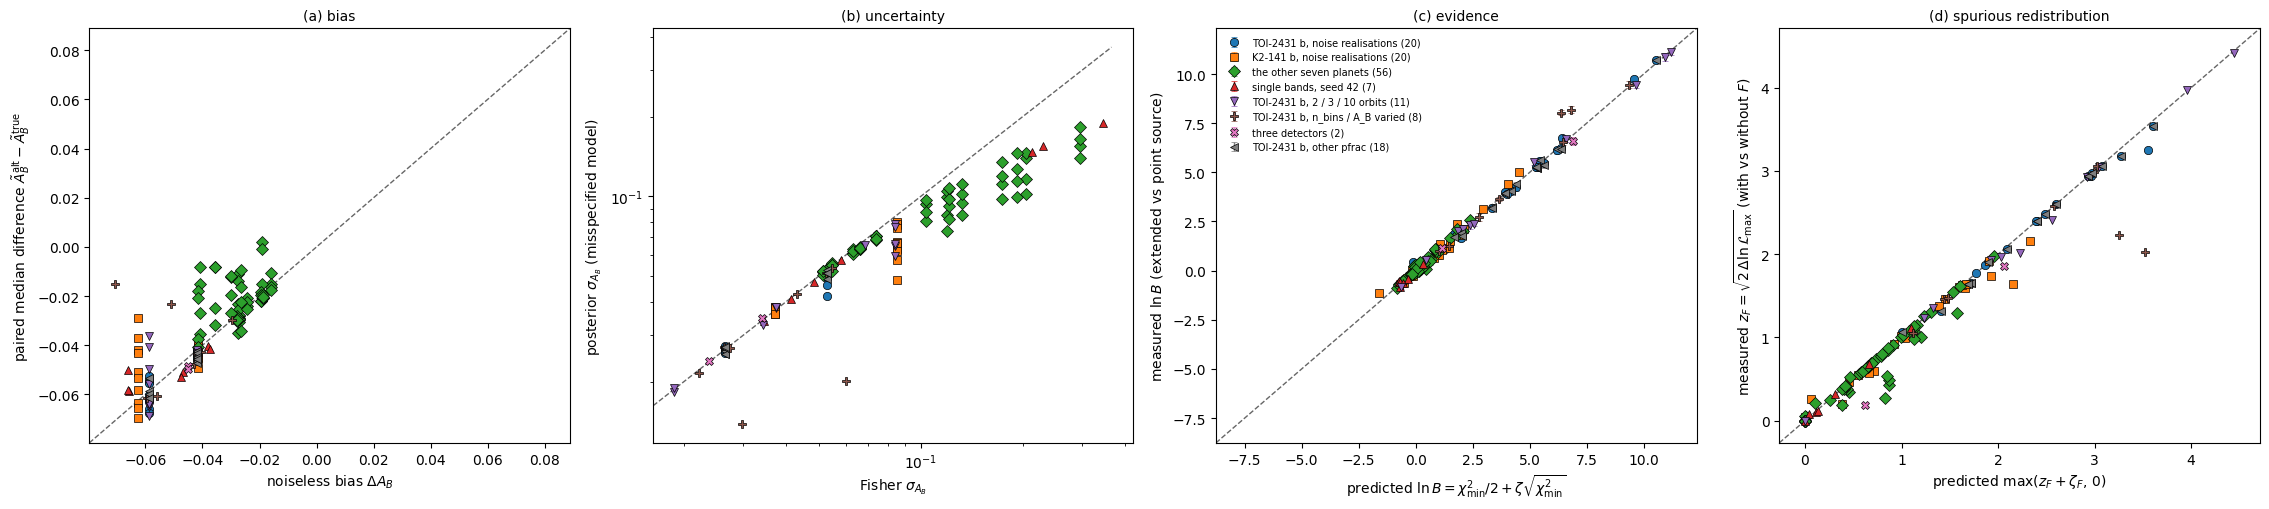

142 of 148 runs shown (null-test and free-geometry runs are compared with their own predictions in the last section)


In [6]:
PAPER_MODE = False
is_ = lambda name: (runs["series"] == name).to_numpy()
normal = (runs["kind"] == "").to_numpy()
ref_T = normal & (runs["planet"] == T).to_numpy() & (runs["n_orbits"] == 5).to_numpy() & (runs["n_bins"] == 27).to_numpy() & (runs["A_B_true"] == 0.2).to_numpy() & runs["mode"].isin(["joint NIRSpec", "MIRI/LRS"]).to_numpy()
paper = runs["series"].isin(PAPER_SERIES).to_numpy()
GROUPS = {"TOI-2431 b, noise realisations": paper & (runs["planet"] == T).to_numpy(),
          "K2-141 b, noise realisations": paper & (runs["planet"] == K).to_numpy(),
          "the other seven planets": paper & ~runs["planet"].isin([T, K]).to_numpy(),
          "single bands, seed 42": is_("seed 42, single bands"),
          "TOI-2431 b, 2 / 3 / 10 orbits": normal & (runs["planet"] == T).to_numpy() & (runs["n_orbits"] != 5).to_numpy(),
          "TOI-2431 b, n_bins / A_B varied": normal & (runs["planet"] == T).to_numpy() & (runs["n_orbits"] == 5).to_numpy() & ((runs["n_bins"] != 27) | (runs["A_B_true"] != 0.2)).to_numpy(),
          "three detectors": normal & (runs["mode"] == "NIRSpec + LRS").to_numpy(),
          "TOI-2431 b, other pfrac": ref_T & (runs["pfrac"] != 0.8).to_numpy()}
shown = np.any(list(GROUPS.values()), axis=0)
fig, axes = plot_ns_check(runs, groups=GROUPS)
paper_figure("ns_check", PAPER_MODE, fig=fig)
plt.show()
print(f"{int(shown.sum())} of {len(runs)} runs shown (null-test and free-geometry runs are compared with their own predictions in the last section)")

## 4. Same seed, other number of orbits

`simulate_data` draws the noise as $\sigma_{\rm bin}\,z$ from `default_rng(seed)`, so one seed gives the same $z$ for any number of orbits, and $\sigma_{\rm bin} \propto 1/\sqrt{n_{\rm orbits}}$. Runs of the same planet, mode and seed therefore share $\zeta$, and the likelihood-ratio statistic at $n$ orbits follows from the 5-orbit numbers alone:
$$2\,\Delta\ln\mathcal{L}_{\max}(n) = \tfrac{n}{5}\chi^2_{\min} + 2\zeta\sqrt{\tfrac{n}{5}\chi^2_{\min}} .$$
The cell pairs every run at another number of orbits with the baseline run of the same seed and compares the scaled prediction with the measured $2\,\Delta\ln\mathcal{L}_{\max}$ and $\ln B$.

What to look for: the shared $\zeta$ (the two `zeta` columns agree), and the scaled prediction against the measurement.

In [7]:
key = ["planet", "mode", "seed"]
five = runs[(runs["kind"] == "") & (runs["n_orbits"] == 5) & (runs["n_bins"] == 27) & (runs["A_B_true"] == 0.2)].sort_values("pfrac").drop_duplicates(key, keep="last").set_index(key)   # the pfrac 0.8 / 1 run where a seed has several
rows = []
for _, r in runs[(runs["kind"] == "") & (runs["n_orbits"] != 5)].iterrows():
    k = (r["planet"], r["mode"], r["seed"])
    if k not in five.index: rows.append(dict(planet=k[0], mode=k[1], seed=k[2], n_orbits=r["n_orbits"], note="no 5-orbit run of this seed")); continue
    b = five.loc[k]
    c = r["n_orbits"] / 5. * b["chi2_min"]
    rows.append(dict(planet=k[0], mode=k[1], seed=k[2], n_orbits=r["n_orbits"], zeta_5=b["zeta"], zeta_n=r["zeta"], dchi2_scaled=c + 2. * b["zeta"] * np.sqrt(c), dchi2_measured=2. * r["dlnL_max"],
                     lnB_scaled=0.5 * c + b["zeta"] * np.sqrt(c), lnB_measured=r["lnB"], lnB_err=r["lnB_err_jitter"]))
print(pd.DataFrame(rows).sort_values(["planet", "mode", "seed", "n_orbits"]).to_string(index=False, float_format=lambda v: f"{v:.3g}") if rows else "no run at another number of orbits yet")

    planet          mode  seed  n_orbits  zeta_5  zeta_n  dchi2_scaled  dchi2_measured  lnB_scaled  lnB_measured  lnB_err
TOI-2431 b      MIRI/LRS    42         3   -1.21   -1.21         0.942            1.05       0.471         0.566    0.112
TOI-2431 b      MIRI/LRS    42        10   -1.21   -1.21          13.2            13.3         6.6          6.69    0.133
TOI-2431 b      MIRI/LRS    43         2  -0.298  -0.298          3.74            3.64        1.87          2.04    0.115
TOI-2431 b      MIRI/LRS    43        10  -0.298  -0.298          22.4            22.3        11.2          11.1    0.143
TOI-2431 b      MIRI/LRS    44         2  0.0129  0.0129          5.14            5.13        2.57          2.39    0.108
TOI-2431 b      MIRI/LRS    45         2    1.17    1.17          10.4            10.6        5.18          5.52    0.127
TOI-2431 b      MIRI/LRS    46         2  -0.202  -0.202          4.17            4.13        2.08          2.12    0.113
TOI-2431 b      MIRI/LRS

## 5. Measured only: the point-source model with redistribution, and the two pfrac

**Fits with redistribution.** For every run with a `naive_redist` fit: $\ln B$ of the truth's model against it, $\ln B$ of the point-source model with against without redistribution, and the posterior of $F$ (median, half-width of the 16-84 % interval, 95 % upper limit). No prediction of these Bayes factors: the prior of $F$ contributes an Occam term of several nats and the posterior of $F$ is one-sided. `occam_F` is that term for the pair with and without redistribution, $\ln B - \Delta\ln\mathcal{L}_{\max}$; it is set by the width of the $F$ prior against the posterior, so a narrower prior $U(0, w)$ that still contains the posterior shifts every $\ln B$ with redistribution by $\ln(0.5/w)$. `zF_obs` is the likelihood-ratio significance of $F$ in that realisation (section 2 and 7 compare it with its prediction). The noiseless context ($\chi^2/2$ of that fit, the likelihood part) is in `Evidence_Prediction.ipynb`, section 2.

**pfrac.** Where the same data were sampled at two pfrac, the differences of $\ln B$ and of the $A_B$ posterior between the two runs, to judge whether the weighting of the sampler matters at the precision needed here.

In [8]:
red = runs[runs["lnB_vs_redist"].notna()]
cols = ["planet", "mode", "kind", "A_B_true", "n_bins", "n_orbits", "seed", "pfrac", "lnB_ext_vs_ps", "lnB_vs_redist", "lnB_redist_vs_ps", "occam_F", "zF_obs", "F_med", "F_sigma", "F_95"]
print(red.assign(F_ratio=red["F_med"] / red["F_sigma"])[cols + ["F_ratio"]].sort_values(["kind", "planet", "mode", "A_B_true", "n_bins", "n_orbits", "seed", "pfrac"]).to_string(index=False, float_format=lambda v: f"{v:.3g}") if len(red) else "no run with a fit with redistribution")

# the same data (planet, mode, settings, seed) at two pfrac
same = ["planet", "mode", "kind", "A_B_true", "n_bins", "n_orbits", "seed"]
pairs = []
for k, g in runs.groupby(same):
    if g["pfrac"].nunique() < 2: continue
    g = g.sort_values("pfrac")
    a, b = g.iloc[0], g.iloc[-1]
    pairs.append(dict(zip(same, k), pfrac_a=a["pfrac"], pfrac_b=b["pfrac"], d_lnB=b["lnB"] - a["lnB"], d_lnB_vs_redist=b["lnB_vs_redist"] - a["lnB_vs_redist"],
                      d_A_B_med_ps=b["A_B_med_alt"] - a["A_B_med_alt"], d_sigma_post=b["sigma_post"] - a["sigma_post"]))
print("\nsame data at two pfrac (b - a):")
print(pd.DataFrame(pairs).drop(columns=["kind", "A_B_true", "n_bins", "n_orbits"]).to_string(index=False, float_format=lambda v: f"{v:.3g}") if pairs else "   no dataset sampled at two pfrac")

     planet          mode      kind  A_B_true  n_bins  n_orbits  seed  pfrac  lnB_ext_vs_ps  lnB_vs_redist  lnB_redist_vs_ps  occam_F  zF_obs   F_med  F_sigma    F_95  F_ratio
 HD 80653 b      MIRI/LRS                 0.2      27         5    40    0.8           1.68           6.12             -4.44    -4.66   0.651   0.003  0.00289  0.0102     1.04
 HD 80653 b      MIRI/LRS                 0.2      27         5    41    0.8         -0.189           4.08             -4.27    -4.51   0.691 0.00337  0.00318  0.0112     1.06
 HD 80653 b      MIRI/LRS                 0.2      27         5    42    0.8         -0.752           4.16             -4.92    -4.91       0 0.00221  0.00237 0.00828    0.933
 HD 80653 b      MIRI/LRS                 0.2      27         5    43    0.8          0.431           4.67             -4.24    -4.72   0.977 0.00335  0.00305  0.0106      1.1
 HD 80653 b joint NIRSpec                 0.2      27         5    40    0.8          0.468           3.55             -

## 6. Special runs against their predictions

The runs that probe one assumption each, every one compared with a prediction made before sampling. They enter the table of section 1 through their series; this section adds what is specific to each. Runs that are still queued are listed as missing.

- **Three detectors** (NRS1 + NRS2 + MIRI/LRS in one fit). The per-run prediction is the same function, on the three-detector set. `chi2_bias_res` repeats the noiseless fit at the resolution of the bias analysis, the number of `Bias_Maps.ipynb` §1.5: the two $\chi^2_{\min}$ must agree up to the resolution difference seen for the single modes.
- **Free geometry** ($a/R_\star$, $R_p/R_\star$ and the inclination sampled with Gaussian priors in every model, in the parametrisation of the planet's source: $b$ for TOI-2431 b, with $i = \arccos[b/(a/R_\star)]$, and $i$ for K2-141 b). The prediction is the linear nuisance fit of `Nuisance_Robustness.ipynb` (row `+ all geometry`) at the truth's resolution, with the run's own priors read from its pickles: `chi2_min` and `sigma_fisher` are those of the marginalised fit (`chi2_min_fixed`, `sigma_fisher_fixed`: the fixed-geometry values), and $\zeta$ uses the augmented residual. `<name>_shrink` is the posterior width of a geometry parameter under the point-source model over its prior width, next to the linear prediction. A run that holds $i$ fixed (the design before 2026-11-11) is flagged if $a/R_\star$ comes out much narrower than its prior: the fixed inclination then pins the geometry, and the run understates $\sigma_{A_B}$ (relative to the row `+ all geometry` of the nuisance table, by 5–19 % for TOI-2431 b, depending on the mode, at $A_B$ = 0.2, 5 orbits).
- **Null test** (the data are drawn from the point-source model). Now the extended-source model is the misspecified one: $\ln B({\rm ext\ vs\ ps}) \approx -(\chi^2_{\rm null}/2 + \zeta'\sqrt{\chi^2_{\rm null}})$ with $\chi^2_{\rm null}$ and $r'$ from the noiseless fit of the extended-source model to the point-source truth. `dA_noiseless` is then the bias of the extended-source model, expected positive.
- **$A_B = 0.05$.** The noiseless point-source fit lies below $A_B = 0$, where the retrieval's prior ends, so the posterior piles up at the edge and the linear theory does not apply. The cell prints the prediction twice, from the unbounded noiseless fit (`A_B_FIT_BOUNDS`) and from the fit held at the floor (`A_B_BOUNDS`), next to the measurement, and the noiseless fits with redistribution for both ranges next to the posterior of $F$.
- **2 orbits.** The same seeds as 5-orbit runs, so each run is predicted from its 5-orbit partner by the scaling of section 4, which lists them.

What to look for: the measured $\ln B$ against `lnB_pred` in every block (the sign flips for the null test), and where the prediction is not expected to hold: the $A_B = 0.05$ runs, and any run whose point-source posterior touches $A_B = 0$.

In [9]:
SPECIAL = ["three detectors", "free geometry", "null test", "TOI-2431 b, A_B = 0.05", "TOI-2431 b LRS, 2 orbits"]
sp = tab[tab["series"].isin(SPECIAL)]
n_missing = {name: sum(1 for m in missing if m[0] == name) for name in SPECIAL}
print("special runs stored / still missing: " + ", ".join(f"{name}: {int((sp['series'] == name).sum())} / {n_missing[name]}" for name in SPECIAL))

cols = ["series", "planet", "mode", "n_orbits", "seed", "chi2_min", "lnB_expected", "zeta", "lnB_pred_ext_vs_ps", "lnB_ext_vs_ps", "lnB_err_jitter", "A_B_med_alt", "dA_noiseless", "dA_median", "sigma_fisher", "sigma_post"]
if len(sp):
    sgn = np.where(sp["truth"] == "hyperillum", 1., -1.)   # ln B in the orientation extended source vs point source: the expectation is -chi2_null / 2 for a null test
    print(sp.assign(lnB_expected=sgn * sp["lnB_expected"])[cols].to_string(index=False, float_format=lambda v: f"{v:.3g}"))
else:
    print("no special run stored yet")

# --- three detectors: the noiseless chi2_min again at the resolution of the bias analysis (Bias_Maps.ipynb 1.5)
for _, r in sp[sp["series"] == "three detectors"].iterrows():
    fits = load_fits(os.path.join(RESULTS_DIR, r["stem"] + "_*.pkl"))
    c2 = fit_naive(fits["naive"].meta["cfg"], [model_pcurve(c, "hyperillum", r["A_B_true"])[1] for c in fits["naive"].meta["cfg"]])[1]
    print(f"\nthree detectors, {r['planet']}: chi2_min = {r['chi2_min']:.3f} at the truth's resolution, {c2:.3f} at the resolution of the bias analysis (chi2_bias_res)")

# --- free geometry: marginalised against fixed-geometry prediction, and the shrinkage of the geometry priors
fg = sp[sp["series"] == "free geometry"]
if len(fg):
    print("\nfree geometry:")
    shrink = [f"{n}_{s}" for n in ("a_rs", "rp_rs", "b", "incl") for s in ("shrink", "shrink_pred") if f"{n}_{s}" in fg]   # the sampled geometry: b for TOI-2431 b, incl for K2-141 b
    print(fg[["planet", "mode", "seed", "chi2_min_fixed", "chi2_min", "sigma_fisher_fixed", "sigma_fisher", "sigma_post", *shrink, "A_B_med_alt", "A_B_med_truth"]].to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.3g}"))
    i_fixed = fg.filter(regex="^(b|incl)_shrink$").isna().all(axis=1)   # runs that sample neither b nor i
    pinned = fg[(fg["a_rs_shrink"] < 0.5) & i_fixed]
    if len(pinned): print("   a/R* posterior narrower than half its prior in " + ", ".join(f"{r['planet']} {r['mode']} ({r['a_rs_shrink']:.2f})" for _, r in pinned.iterrows()) + ": the fixed inclination pins the geometry (see the text above)")
    edge = fg[fg["A_B_med_alt"] - 2. * fg["sigma_post"] < 0.]
    if len(edge): print("   point-source posterior within 2 sigma of A_B = 0 (prior edge, the linear prediction is not expected to hold): " + ", ".join(f"{r['planet']} {r['mode']}" for _, r in edge.iterrows()))

# --- A_B = 0.05: the prediction from the noiseless fit held at the physical floor, and the noiseless fits with redistribution for both ranges (resolution of the bias analysis)
for _, r in sp[sp["series"] == "TOI-2431 b, A_B = 0.05"].iterrows():
    fits = load_fits(os.path.join(RESULTS_DIR, r["stem"] + "_*.pkl"))
    b = run_prediction(fits, ref=evidence_reference(fits, A_B_bounds=A_B_BOUNDS), K=0)
    print(f"\nA_B = 0.05, {r['planet']} {r['mode']} seed {r['seed']}: measured ln B = {r['lnB']:.2f} +- {r['lnB_err_jitter'] if np.isfinite(r['lnB_err_jitter']) else r['lnB_err']:.2f};  point-source posterior A_B = {r['A_B_med_alt']:.3f} +- {r['sigma_post']:.3f}")
    print(f"   unbounded noiseless fit: A_B = {r['A_B_true'] + r['dA_noiseless']:+.4f}, chi2_min = {r['chi2_min']:.2f}, predicted ln B = {r['lnB_pred']:.2f}  (measured - predicted {r['lnB'] - r['lnB_pred']:+.2f})")
    print(f"   held at A_B >= 0:        A_B = {b['A_B_true'] + b['dA_noiseless']:+.4f}, chi2_min = {b['chi2_min']:.2f}, predicted ln B = {b['lnB_pred']:.2f}  (measured - predicted {r['lnB'] - b['lnB_pred']:+.2f})")
    cfg_ = fits["naive"].meta["cfg"]
    for rng, lab in ((A_B_FIT_BOUNDS, "unbounded"), (A_B_BOUNDS, "A_B >= 0")):
        j = fit_truth(cfg_, r["A_B_true"], models=("naive_redist",), bounds=rng)["naive_redist"]
        print(f"   noiseless fit with redistribution, {lab:9s}: A_B = {j['A_B_fit']:+.4f}, F = {j['F_fit']:.4f}" + (f"   (posterior: F = {r['F_med']:.4f} +- {r['F_sigma']:.4f}, < {r['F_95']:.4f} at 95 %)" if "F_med" in r and np.isfinite(r["F_med"]) else ""))

special runs stored / still missing: three detectors: 2 / 0, free geometry: 0 / 12, null test: 6 / 0, TOI-2431 b, A_B = 0.05: 2 / 0, TOI-2431 b LRS, 2 orbits: 5 / 0
                  series     planet          mode  n_orbits  seed  chi2_min  lnB_expected    zeta  lnB_pred_ext_vs_ps  lnB_ext_vs_ps  lnB_err_jitter  A_B_med_alt  dA_noiseless  dA_median  sigma_fisher  sigma_post
         three detectors TOI-2431 b NIRSpec + LRS         5    43      24.4          12.2   -1.08                6.88            6.6            0.19         0.14       -0.0452    -0.0485        0.0237       0.024
         three detectors   K2-141 b NIRSpec + LRS         5    43      9.36          4.68   -1.15                1.17           1.16           0.185        0.137       -0.0451    -0.0497        0.0341      0.0348
               null test TOI-2431 b joint NIRSpec         5    43      10.8         -5.39   0.193               -6.03          -6.12           0.176        0.231        0.0452     0.0465        0.


three detectors, TOI-2431 b: chi2_min = 24.421 at the truth's resolution, 24.305 at the resolution of the bias analysis (chi2_bias_res)



three detectors, K2-141 b: chi2_min = 9.360 at the truth's resolution, 9.324 at the resolution of the bias analysis (chi2_bias_res)



A_B = 0.05, TOI-2431 b joint NIRSpec seed 43: measured ln B = 8.18 +- 0.18;  point-source posterior A_B = 0.014 +- 0.014
   unbounded noiseless fit: A_B = -0.0011, chi2_min = 14.78, predicted ln B = 6.82  (measured - predicted +1.36)
   held at A_B >= 0:        A_B = +0.0000, chi2_min = 14.78, predicted ln B = 6.85  (measured - predicted +1.34)


   noiseless fit with redistribution, unbounded: A_B = -0.0661, F = 0.0132   (posterior: F = 0.0086 +- 0.0036, < 0.0147 at 95 %)


   noiseless fit with redistribution, A_B >= 0 : A_B = +0.0000, F = 0.0092   (posterior: F = 0.0086 +- 0.0036, < 0.0147 at 95 %)



A_B = 0.05, TOI-2431 b MIRI/LRS seed 43: measured ln B = 8.04 +- 0.13;  point-source posterior A_B = 0.018 +- 0.020
   unbounded noiseless fit: A_B = -0.0207, chi2_min = 15.03, predicted ln B = 6.37  (measured - predicted +1.67)
   held at A_B >= 0:        A_B = +0.0000, chi2_min = 15.15, predicted ln B = 6.85  (measured - predicted +1.19)


   noiseless fit with redistribution, unbounded: A_B = -0.1564, F = 0.0055   (posterior: F = 0.0031 +- 0.0017, < 0.0062 at 95 %)


   noiseless fit with redistribution, A_B >= 0 : A_B = +0.0000, F = 0.0035   (posterior: F = 0.0031 +- 0.0017, < 0.0062 at 95 %)


## 7. The retrievals of the paper (Sec. 4.4)

The series of `PAPER_SERIES`: every paper planet at the baseline settings in the joint NIRSpec fit and in MIRI/LRS, sampled with the extended-source model, the point-source model and the point-source model with redistribution, over the noise realisations of `PAPER_SEEDS`. Four tables, one row per planet and mode (mean ± standard deviation over the realisations):

- **Evidence.** The noiseless expectation $\chi^2_{\min}/2 \pm \sqrt{\chi^2_{\min}}$ next to the measured $\ln B$ (extended vs point source) with its range, the difference to the per-run prediction, the mean $\zeta$ of the realisations, and how many realisations exceed $\ln B = 2.5$ and $5$ next to the probability the Gaussian prediction gives (`evidence_probability`).
- **$A_B$-only fit.** The paired median difference against the noiseless bias and the posterior width against the Fisher $\sigma$.
- **Fit with redistribution.** The same two comparisons for its $A_B$, the posterior median of $F$ against the noiseless fitted $F$, the significance $z_F$ of $F$ per realisation against its noiseless value and its per-run prediction, the nightside temperature of the fit, and the two Bayes factors that involve this model with the Occam term of $F$.
- **Coverage.** The number of realisations in which the central 95 % interval of $A_B$ excludes the injected value, for each of the three models. For a model that describes the data this happens in about one realisation in twenty. The realisations of all planets and modes share their standardised noise, so the counts of different rows are not independent.

What to look for: the measured $\ln B$ follows the per-run prediction for every planet, while its mean over the realisations need not equal $\chi^2_{\min}/2$: all series share the same few noise vectors (the same seeds), so their $\zeta$ are strongly correlated between planets and the mean of $\zeta$ over a handful of seeds is not zero (last cell of this section). The paired median difference and the posterior width follow the noiseless values where the Fisher $\sigma$ is small against the distance of the fit from $A_B = 0$, and fall below them where the prior cuts the posterior (MIRI/LRS for most planets, and the fit with redistribution of every planet in MIRI/LRS). The Bayes factor of the extended-source model against the fit with redistribution is positive for every planet, including those whose data cannot tell the models apart: it is dominated by the Occam term of $F$ (compare `ln B (ext vs ps+F)` with `−Occam`).


In [10]:
paper = runs[runs["series"].isin(PAPER_SERIES)]
by = ["planet", "mode"]
summ = series_summary(paper, by=by)
g = paper.groupby(by, sort=False)
both7 = lambda name, f="{:.2f}", fs=None: [f.format(m) + ("" if pd.isna(s) else " ± " + (fs or f).format(s)) for m, s in zip(summ[name], summ[name + " sd"])]   # mean ± sd over the realisations (fs: format of the sd where the mean carries a sign)
span = lambda col, f="{:.2f}": [f.format(lo) + " … " + f.format(hi) for lo, hi in zip(g[col].min(), g[col].max())]
count = lambda col, test: [f"{int(k)}/{int(n)}" for k, n in zip(g[col].agg(lambda s: test(s).sum()), summ["n"])]   # realisations that pass a test, of n
chi2 = 2. * summ["lnB_expected"]   # chi2_min of each planet and mode (the same for all its realisations)

print(f"{len(paper)} retrievals of the paper series ({paper['planet'].nunique()} planets, {paper['mode'].nunique()} modes), {int(paper[['planet', 'mode']].drop_duplicates().shape[0])} configurations")
print("\nEvidence: ln B, extended vs point source")
display(pd.DataFrame({"n": summ["n"], "χ²_min/2 ± √χ²_min": [f"{0.5 * c:.2f} ± {np.sqrt(c):.2f}" for c in chi2], "ln B": both7("lnB"), "range": span("lnB"), "ln B − prediction": both7("lnB - pred", "{:+.2f}", "{:.2f}"), "ζ": both7("zeta", "{:+.2f}", "{:.2f}"),
                      "ln B > 2.5": count("lnB", lambda s: s > 2.5), "P(> 2.5)": evidence_probability(chi2, 2.5).round(2), "ln B > 5": count("lnB", lambda s: s > 5.), "P(> 5)": evidence_probability(chi2, 5.).round(2),
                      "ln B < 0": count("lnB", lambda s: s < 0.), "P(< 0)": (1. - evidence_probability(chi2, 0.)).round(2)}))
print("A_B-only fit: paired posterior-median difference (point source − extended source) and posterior width")
display(pd.DataFrame({"n": summ["n"], "ΔA_B, noiseless": summ["dA_noiseless"].map("{:+.4f}".format), "ΔA_B, medians": both7("dA_median", "{:+.4f}", "{:.4f}"), "σ_Fisher": g["sigma_fisher"].first().map("{:.4f}".format),
                      "σ_post / σ_Fisher": both7("sigma_post/sigma_F")}))
print("Fit with redistribution: A_B, F and its significance, nightside temperature, Bayes factors")
display(pd.DataFrame({"ΔA_B, noiseless": summ["dA_noiseless_redist"].map("{:+.4f}".format), "ΔA_B, medians": both7("dA_median_redist", "{:+.4f}", "{:.4f}"), "σ_post / σ_Fisher": both7("sigma_post/sigma_F redist"),
                      "F, noiseless": summ["F_noiseless"].map("{:.4f}".format), "F, median": both7("F_med", "{:.4f}"), "z_F, noiseless": summ["zF_noiseless"].map("{:.2f}".format), "z_F": both7("zF_obs"),
                      "z_F range": span("zF_obs"), "z_F − prediction": both7("zF_obs - pred", "{:+.2f}", "{:.2f}"), "T_night [K]": [pm(m, s, "{:.0f}") for m, s in zip(g["T_night_med"].mean(), g["T_night_med"].std(ddof=1))],
                      "ln B (ps+F vs ps)": both7("lnB_redist_vs_ps"), "range": span("lnB_redist_vs_ps"), "ln B (ext vs ps+F)": both7("lnB_vs_redist"), "range ": span("lnB_vs_redist"), "−Occam": [f"{-m:.2f}" for m in summ["occam_F"]]}))

d = paper["lnB"] - paper["lnB_pred"]
print(f"all {len(paper)} retrievals: ln B − prediction: mean {d.mean():+.2f}, rms {np.sqrt(np.mean(d ** 2)):.2f}, max |.| {d.abs().max():.2f} (mean sampler error {paper['lnB_err_jitter'].mean():.2f});  "
      f"ln B (ext vs ps+F) from {paper['lnB_vs_redist'].min():.2f} to {paper['lnB_vs_redist'].max():.2f};  ln B (ps+F vs ps) from {paper['lnB_redist_vs_ps'].min():.2f} to {paper['lnB_redist_vs_ps'].max():.2f}, "
      f"{int((paper['lnB_redist_vs_ps'] > 0.).sum())} of them positive")

# Coverage: how often the central 95 % interval of A_B excludes the injected value (a model that describes the data: about one realisation in twenty)
outside = lambda tag: (paper["A_B_true"] < paper["A_B_lo95" + tag]) | (paper["A_B_true"] > paper["A_B_hi95" + tag])   # per retrieval; tag: _truth (extended source), _alt (point source), _redist (with F)
per_row = lambda tag: [f"{int(k)}/{int(n)}" for k, n in zip(outside(tag).groupby([paper[c] for c in by], sort=False).sum(), summ["n"])]
print("\nCoverage: realisations whose central 95 % interval of A_B excludes the injected value")
display(pd.DataFrame({"n": summ["n"], "extended source": per_row("_truth"), "point source": per_row("_alt"), "point source with F": per_row("_redist")}))
print(f"all {len(paper)} retrievals: extended source {int(outside('_truth').sum())}, point source {int(outside('_alt').sum())}, point source with F {int(outside('_redist').sum())}")


96 retrievals of the paper series (9 planets, 2 modes), 18 configurations

Evidence: ln B, extended vs point source


n χ²_min/2 ± √χ²_min         ln B         range  \
planet      mode                                                              
TOI-2431 b  joint NIRSpec  10        5.82 ± 3.41  3.79 ± 1.61   1.68 … 6.12   
            MIRI/LRS       10        6.35 ± 3.56  5.18 ± 3.42  0.44 … 10.71   
TOI-2260 b  joint NIRSpec   4        1.81 ± 1.91  1.58 ± 0.76   0.44 … 2.02   
            MIRI/LRS        4        0.99 ± 1.41  0.74 ± 1.48  -0.88 … 2.60   
K2-141 b    joint NIRSpec  10        2.59 ± 2.28  1.20 ± 1.06  -0.28 … 3.14   
            MIRI/LRS       10        2.07 ± 2.03  1.50 ± 2.04  -1.12 … 5.00   
K2-131 b    joint NIRSpec   4        0.46 ± 0.96  0.30 ± 0.23   0.09 … 0.61   
            MIRI/LRS        4        0.19 ± 0.61  0.15 ± 0.67  -0.52 … 1.05   
TOI-561 b   joint NIRSpec   4        0.81 ± 1.27  0.47 ± 0.37   0.09 … 0.93   
            MIRI/LRS        4        0.61 ± 1.10  0.42 ± 1.22  -0.70 … 2.12   
Kepler-78 b joint NIRSpec   4        0.15 ± 0.55  0.06 ± 0.19  -0.17 … 0.25   
            MIRI/LRS        4        0.08 ± 0.40  0.07 ± 0.46  -0.37 … 0.69   
TOI-1444 b  joint NIRSpec   4        0.34 ± 0.82  0.15 ± 0.18  -0.08 … 0.29   
            MIRI/LRS        4        0.20 ± 0.63  0.14 ± 0.67  -0.52 … 1.02   
TOI-1798.02 joint NIRSpec   4        0.26 ± 0.72  0.08 ± 0.18  -0.12 … 0.26   
            MIRI/LRS        4        0.17 ± 0.59  0.13 ± 0.70  -0.55 … 1.08   
HD 80653 b  joint NIRSpec   4        0.54 ± 1.04  0.36 ± 0.16   0.13 … 0.47   
            MIRI/LRS        4        0.43 ± 0.93  0.29 ± 1.04  -0.75 … 1.68   

                          ln B − prediction             ζ ln B > 2.5  \
planet      mode                                                       
TOI-2431 b  joint NIRSpec      -0.06 ± 0.15  -0.58 ± 0.46       7/10   
            MIRI/LRS           +0.07 ± 0.24  -0.35 ± 0.96       7/10   
TOI-2260 b  joint NIRSpec      -0.03 ± 0.08  -0.11 ± 0.37        0/4   
            MIRI/LRS           +0.08 ± 0.18  -0.24 ± 0.95        1/4   
K2-141 b    joint NIRSpec      -0.07 ± 0.17  -0.58 ± 0.44       1/10   
            MIRI/LRS           +0.16 ± 0.29  -0.36 ± 0.95       2/10   
K2-131 b    joint NIRSpec      -0.01 ± 0.08  -0.15 ± 0.21        0/4   
            MIRI/LRS           +0.14 ± 0.11  -0.29 ± 0.98        0/4   
TOI-561 b   joint NIRSpec      -0.15 ± 0.16  -0.16 ± 0.21        0/4   
            MIRI/LRS           +0.14 ± 0.16  -0.29 ± 0.98        0/4   
Kepler-78 b joint NIRSpec      -0.04 ± 0.09  -0.10 ± 0.31        0/4   
            MIRI/LRS           +0.08 ± 0.07  -0.22 ± 1.02        0/4   
TOI-1444 b  joint NIRSpec      -0.07 ± 0.05  -0.14 ± 0.22        0/4   
            MIRI/LRS           +0.12 ± 0.12  -0.28 ± 0.99        0/4   
TOI-1798.02 joint NIRSpec      -0.08 ± 0.05  -0.14 ± 0.21        0/4   
            MIRI/LRS           +0.11 ± 0.12  -0.27 ± 1.01        0/4   
HD 80653 b  joint NIRSpec      -0.05 ± 0.11  -0.13 ± 0.25        0/4   
            MIRI/LRS           +0.09 ± 0.14  -0.25 ± 1.02        0/4   

                           P(> 2.5) ln B > 5  P(> 5) ln B < 0  P(< 0)  
planet      mode                                                       
TOI-2431 b  joint NIRSpec      0.83     3/10    0.60     0/10    0.04  
            MIRI/LRS           0.86     6/10    0.65     0/10    0.04  
TOI-2260 b  joint NIRSpec      0.36      0/4    0.05      0/4    0.17  
            MIRI/LRS           0.14      0/4    0.00      1/4    0.24  
K2-141 b    joint NIRSpec      0.52     0/10    0.14     1/10    0.13  
            MIRI/LRS           0.42     1/10    0.07     3/10    0.15  
K2-131 b    joint NIRSpec      0.02      0/4    0.00      0/4    0.32  
            MIRI/LRS           0.00      0/4    0.00      2/4    0.38  
TOI-561 b   joint NIRSpec      0.09      0/4    0.00      0/4    0.26  
            MIRI/LRS           0.04      0/4    0.00      2/4    0.29  
Kepler-78 b joint NIRSpec      0.00      0/4    0.00      2/4    0.39  
            MIRI/LRS           0.00      0/4    0.00      2/4    0.42 

A_B-only fit: paired posterior-median difference (point source − extended source) and posterior width


n ΔA_B, noiseless     ΔA_B, medians σ_Fisher  \
planet      mode                                                           
TOI-2431 b  joint NIRSpec  10         -0.0418  -0.0440 ± 0.0019   0.0265   
            MIRI/LRS       10         -0.0588  -0.0597 ± 0.0052   0.0530   
TOI-2260 b  joint NIRSpec   4         -0.0272  -0.0288 ± 0.0010   0.0541   
            MIRI/LRS        4         -0.0274  -0.0208 ± 0.0109   0.1327   
K2-141 b    joint NIRSpec  10         -0.0416  -0.0438 ± 0.0027   0.0372   
            MIRI/LRS       10         -0.0626  -0.0512 ± 0.0133   0.0853   
K2-131 b    joint NIRSpec   4         -0.0271  -0.0284 ± 0.0021   0.0632   
            MIRI/LRS        4         -0.0409  -0.0215 ± 0.0122   0.2051   
TOI-561 b   joint NIRSpec   4         -0.0278  -0.0292 ± 0.0010   0.0515   
            MIRI/LRS        4         -0.0417  -0.0292 ± 0.0115   0.1196   
Kepler-78 b joint NIRSpec   4         -0.0160  -0.0149 ± 0.0030   0.1035   
            MIRI/LRS        4         -0.0191  -0.0083 ± 0.0103   0.2943   
TOI-1444 b  joint NIRSpec   4         -0.0242  -0.0232 ± 0.0020   0.0740   
            MIRI/LRS        4         -0.0355  -0.0182 ± 0.0120   0.1927   
TOI-1798.02 joint NIRSpec   4         -0.0193  -0.0206 ± 0.0018   0.0660   
            MIRI/LRS        4         -0.0299  -0.0176 ± 0.0073   0.1735   
HD 80653 b  joint NIRSpec   4         -0.0188  -0.0204 ± 0.0006   0.0548   
            MIRI/LRS        4         -0.0264  -0.0207 ± 0.0105   0.1215   

                          σ_post / σ_Fisher  
planet      mode                             
TOI-2431 b  joint NIRSpec       1.00 ± 0.02  
            MIRI/LRS            0.94 ± 0.06  
TOI-2260 b  joint NIRSpec       1.00 ± 0.02  
            MIRI/LRS            0.74 ± 0.09  
K2-141 b    joint NIRSpec       1.00 ± 0.02  
            MIRI/LRS            0.79 ± 0.12  
K2-131 b    joint NIRSpec       0.98 ± 0.02  
            MIRI/LRS            0.61 ± 0.10  
TOI-561 b   joint NIRSpec       1.01 ± 0.02  
            MIRI/LRS            0.76 ± 0.12  
Kepler-78 b joint NIRSpec       0.87 ± 0.07  
            MIRI/LRS            0.54 ± 0.06  
TOI-1444 b  joint NIRSpec       0.95 ± 0.02  
            MIRI/LRS            0.63 ± 0.10  
TOI-1798.02 joint NIRSpec       0.97 ± 0.01  
            MIRI/LRS            0.67 ± 0.09  
HD 80653 b  joint NIRSpec       1.00 ± 0.03  
            MIRI/LRS            0.78 ± 0.09

Fit with redistribution: A_B, F and its significance, nightside temperature, Bayes factors


ΔA_B, noiseless     ΔA_B, medians σ_post / σ_Fisher  \
planet      mode                                                                
TOI-2431 b  joint NIRSpec         -0.0939  -0.0865 ± 0.0119       0.98 ± 0.04   
            MIRI/LRS              -0.1686  -0.1192 ± 0.0174       0.61 ± 0.18   
TOI-2260 b  joint NIRSpec         -0.0932  -0.0864 ± 0.0138       0.74 ± 0.08   
            MIRI/LRS              -0.1594  -0.0657 ± 0.0190       0.43 ± 0.09   
K2-141 b    joint NIRSpec         -0.0840  -0.0768 ± 0.0110       0.90 ± 0.05   
            MIRI/LRS              -0.1555  -0.0889 ± 0.0245       0.55 ± 0.15   
K2-131 b    joint NIRSpec         -0.0567  -0.0662 ± 0.0085       0.78 ± 0.06   
            MIRI/LRS              -0.1086  -0.0496 ± 0.0205       0.42 ± 0.09   
TOI-561 b   joint NIRSpec         -0.0590  -0.0683 ± 0.0107       0.85 ± 0.03   
            MIRI/LRS              -0.1121  -0.0639 ± 0.0201       0.51 ± 0.10   
Kepler-78 b joint NIRSpec         -0.0525  -0.0582 ± 0.0109       0.55 ± 0.10   
            MIRI/LRS              -0.1085  -0.0426 ± 0.0130       0.32 ± 0.05   
TOI-1444 b  joint NIRSpec         -0.0534  -0.0616 ± 0.0075       0.72 ± 0.08   
            MIRI/LRS              -0.1009  -0.0485 ± 0.0183       0.44 ± 0.09   
TOI-1798.02 joint NIRSpec         -0.0431  -0.0600 ± 0.0101       0.75 ± 0.05   
            MIRI/LRS              -0.0866  -0.0477 ± 0.0129       0.44 ± 0.08   
HD 80653 b  joint NIRSpec         -0.0485  -0.0651 ± 0.0131       0.79 ± 0.04   
            MIRI/LRS              -0.0970  -0.0609 ± 0.0164       0.47 ± 0.09   

                          F, noiseless        F, median z_F, noiseless  \
planet      mode                                                         
TOI-2431 b  joint NIRSpec       0.0141  0.0117 ± 0.0027           2.49   
            MIRI/LRS            0.0058  0.0049 ± 0.0012           2.84   
TOI-2260 b  joint NIRSpec       0.0091  0.0092 ± 0.0023           1.34   
            MIRI/LRS            0.0037  0.0037 ± 0.0007           1.08   
K2-141 b    joint NIRSpec       0.0102  0.0081 ± 0.0024           1.51   
            MIRI/LRS            0.0040  0.0035 ± 0.0010           1.51   
K2-131 b    joint NIRSpec       0.0072  0.0101 ± 0.0022           0.57   
            MIRI/LRS            0.0028  0.0061 ± 0.0009           0.41   
TOI-561 b   joint NIRSpec       0.0068  0.0085 ± 0.0020           0.75   
            MIRI/LRS            0.0025  0.0032 ± 0.0006           0.74   
Kepler-78 b joint NIRSpec       0.0080  0.0144 ± 0.0024           0.33   
            MIRI/LRS            0.0033  0.0110 ± 0.0014           0.27   
TOI-1444 b  joint NIRSpec       0.0066  0.0101 ± 0.0020           0.48   
            MIRI/LRS            0.0025  0.0057 ± 0.0010           0.42   
TOI-1798.02 joint NIRSpec       0.0067  0.0116 ± 0.0024           0.40   
            MIRI/LRS            0.0026  0.0056 ± 0.0009           0.38   
HD 80653 b  joint NIRSpec       0.0054  0.0081 ± 0.0021           0.58   
            MIRI/LRS            0.0021  0.0030 ± 0.0005           0.60   

                                   z_F    z_F range z_F − prediction  \
planet      mode                                                       
TOI-2431 b  joint NIRSpec  2.01 ± 0.60  1.06 … 2.94     -0.01 ± 0.04   
            MIRI/LRS       2.59 ± 0.84  0.89 … 3.54     -0.05 ± 0.09   
TOI-2260 b  joint NIRSpec  1.42 ± 0.62  0.53 … 1.98     +0.03 ± 0.03   
            MIRI/LRS       0.89 ± 0.57  0.04 … 1.29     -0.08 ± 0.14   
K2-141 b    joint NIRSpec  1.00 ± 0.59  0.21 … 1.92     -0.02 ± 0.10   
            MIRI/LRS       1.24 ± 0.69  0.05 … 2.16     -0.09 ± 0.17   
K2-131 b    joint NIRSpec  0.65 ± 0.45  0.05 … 1.13     +0.01 ± 0.03   
            MIRI/LRS       0.26 ± 0.19  0.00 … 0.43     -0.14 ± 0.21   
TOI-561 b   joint NIRSpec  0.82 ± 0.45  0.21 … 1.31     +0.03 ± 0.06   
            MIRI/LRS       0.58 ± 0.43  0.00 … 1.00     -0.05 ± 0.10   
Kepler-78 b joint NIRSpec  0.57 ± 0.42  0.00 … 1.01     +0.0

all 96 retrievals: ln B − prediction: mean +0.02, rms 0.18, max |.| 0.57 (mean sampler error 0.14);  ln B (ext vs ps+F) from 2.54 to 10.56;  ln B (ps+F vs ps) from -5.28 to 1.01, 3 of them positive

Coverage: realisations whose central 95 % interval of A_B excludes the injected value


n extended source point source point source with F
planet      mode                                                              
TOI-2431 b  joint NIRSpec  10            0/10         7/10                8/10
            MIRI/LRS       10            1/10         5/10                7/10
TOI-2260 b  joint NIRSpec   4             0/4          0/4                 2/4
            MIRI/LRS        4             0/4          0/4                 0/4
K2-141 b    joint NIRSpec  10            0/10         3/10                6/10
            MIRI/LRS       10            1/10         2/10                5/10
K2-131 b    joint NIRSpec   4             0/4          0/4                 0/4
            MIRI/LRS        4             0/4          0/4                 0/4
TOI-561 b   joint NIRSpec   4             0/4          0/4                 2/4
            MIRI/LRS        4             0/4          0/4                 0/4
Kepler-78 b joint NIRSpec   4             0/4          0/4                 0/4
            MIRI/LRS        4             0/4          0/4                 0/4
TOI-1444 b  joint NIRSpec   4             0/4          0/4                 0/4
            MIRI/LRS        4             0/4          0/4                 0/4
TOI-1798.02 joint NIRSpec   4             0/4          0/4                 0/4
            MIRI/LRS        4             0/4          0/4                 0/4
HD 80653 b  joint NIRSpec   4             0/4          0/4                 0/4
            MIRI/LRS        4             0/4          0/4                 0/4

all 96 retrievals: extended source 2, point source 17, point source with F 30


**Figure `ns_realizations_<planet>`.** The noise realisations of a reference planet one by one, joint NIRSpec fit and MIRI/LRS side by side (`plot_ns_realizations`): what each simulated observation returns. (a) the posterior of $A_B$ under the three models (median, 68 % and 95 % intervals), with the injected value and the noiseless fits of the two point-source models; (b) the posterior of $F$ with the noiseless fitted $F$, labelled with the significance $z_F$ of $F$ in that realisation; (c) $\ln B$ of the extended-source over the point-source model, measured and predicted from the noise of that realisation, on the band $\chi^2_{\min}/2 \pm \sqrt{\chi^2_{\min}}$ of the expectation, and $\ln B$ of the point-source model with over without redistribution. A realisation number is a seed in ascending order, so the same number is the same standardised noise in both columns and for both planets.

What to look for: in (a) the three posteriors move together from one realisation to the next (they share the noise), while their offsets stay those of the noiseless fits; in (c) the Bayes factor changes from realisation to realisation by an amount comparable to its expectation, although the offsets in (a) do not. Where the fit with redistribution sits at the prior edge $A_B = 0$ its posterior is cut and its median lies above the noiseless fit. In paper mode the figure is a preview: the enlarged legend can touch the panel titles, and a final-size version belongs in `PaperPlots.ipynb`.


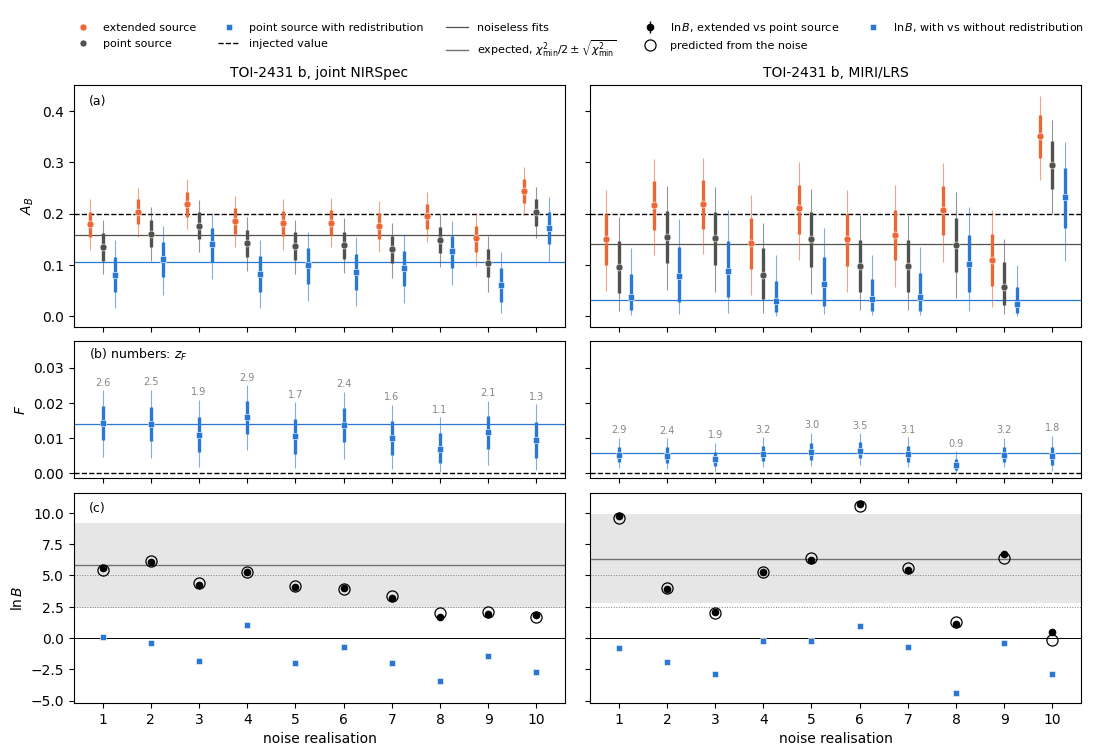

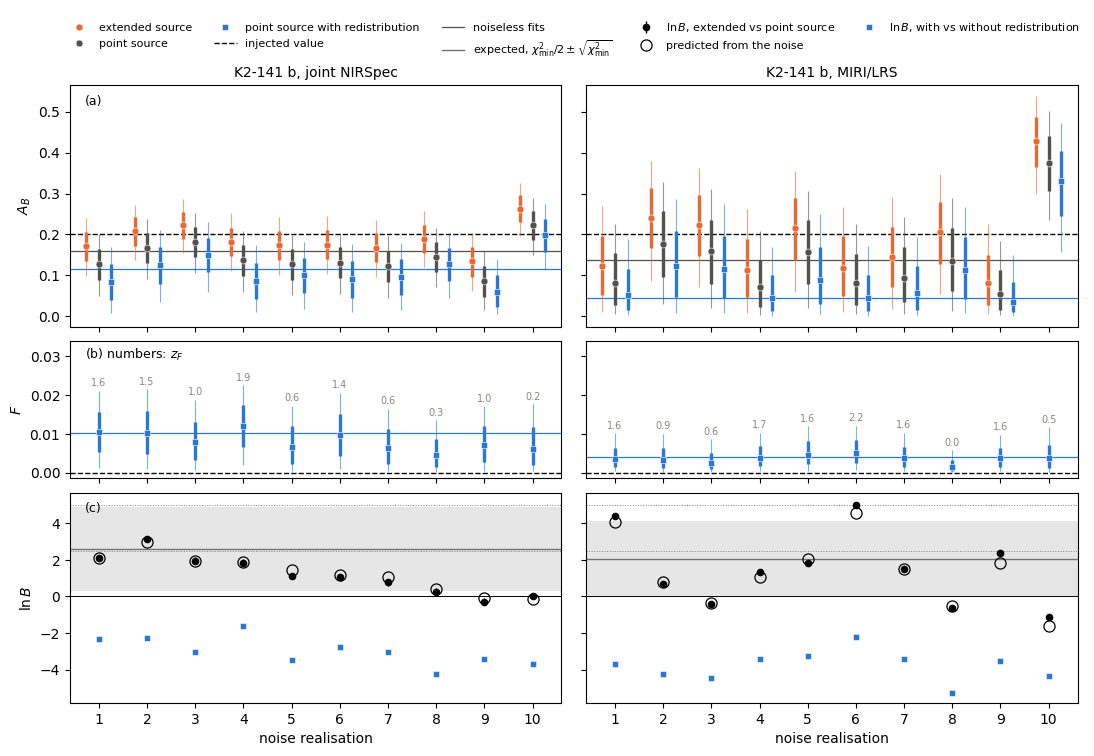

In [11]:
PAPER_MODE = False
for planet in (T, K):
    cols = {f"{planet}, {lab}": (paper["planet"] == planet).to_numpy() & (paper["mode"] == lab).to_numpy() for lab in ("joint NIRSpec", "MIRI/LRS")}
    fig, _ = plot_ns_realizations(paper, cols, figsize=(13., 9.))
    paper_figure(f"ns_realizations_{planet.replace(' ', '')}", PAPER_MODE, fig=fig)
    plt.show()


**How representative are the seeds?** $\zeta$ and the noise power $|z|^2$ of a realisation follow from its seed alone, so their distribution over many seeds costs no sampling. The cell compares the stored realisations of the reference planets with seeds 0–1999 (mean and standard deviation of $\zeta$, the fraction of blocks of consecutive seeds with a mean $\zeta$ as low as the stored block, the mean $|z|^2$ per bin) and lists the $\ln B$ that the linear prediction gives for the next ten seeds, which is what a longer series would return. It also prints the correlation of $\zeta$ between planets and between modes over those seeds: every series draws from the same standardised noise.

What to look for: whether the stored block is a typical draw (mean $\zeta$ within about $\pm 1/\sqrt{n}$ of zero, $|z|^2$ per bin near 1). If it is not, the mean $\ln B$ of the series is not an estimate of $\chi^2_{\min}/2$, and the series should be compared with its per-run predictions only, or extended.


In [12]:
MANY, NEXT = np.arange(2000), np.arange(max(PAPER_SEEDS[T]) + 1, max(PAPER_SEEDS[T]) + 11)   # the seeds of the distribution, and the next ten after the stored block
zeta_of, rows, nxt = {}, [], {}
for name in [f"{p}, {lab}" for p in (T, K) for lab in ("joint NIRSpec", "MIRI/LRS")]:
    t = paper[paper["series"] == name].sort_values("seed")
    ref = evidence_reference(load_fits(os.path.join(RESULTS_DIR, t["stem"].iloc[0] + "_*.pkl")), fisher=False, floor=False)   # r_perp and chi2_min of the configuration (seed-independent)
    r, c2 = ref["r_perp"], ref["chi2"]
    noise = lambda s: np.random.default_rng(int(s)).normal(0., 1., r.size)   # the standardised noise of a seed, as simulate_data draws it
    zeta_of[name] = z_all = np.array([r @ noise(s) / np.sqrt(c2) for s in MANY])
    stored, n = t["zeta"].to_numpy(), len(t)
    blocks = z_all[:len(MANY) // n * n].reshape(-1, n).mean(axis=1)   # means of blocks of n consecutive seeds
    rows.append({"series": name, "n": n, "ζ, stored seeds": f"{stored.mean():+.2f} ± {stored.std(ddof=1):.2f}", "ζ, seeds 0–1999": f"{z_all.mean():+.2f} ± {z_all.std(ddof=1):.2f}",
                 "blocks with a mean ζ this low": f"{np.mean(blocks <= stored.mean()):.3f}", "|z|²/bin, stored": f"{np.mean([noise(s) @ noise(s) for s in t['seed']]) / r.size:.2f}",
                 "|z|²/bin, next ten": f"{np.mean([noise(s) @ noise(s) for s in NEXT]) / r.size:.2f}"})
    nxt[name] = [0.5 * c2 + r @ noise(s) for s in NEXT]   # chi2_min / 2 + zeta sqrt(chi2_min)
display(pd.DataFrame(rows).set_index("series"))
print(f"predicted ln B (extended vs point source) of the next ten seeds, {NEXT[0]}–{NEXT[-1]} (linear prediction, no sampling):")
display(pd.DataFrame(nxt, index=pd.Index(NEXT, name="seed")).T.round(2).assign(mean=lambda f: f.mean(axis=1).round(2)))
print("correlation of ζ between the series over seeds 0–1999 (the same standardised noise in every series):")
display(pd.DataFrame(np.corrcoef(list(zeta_of.values())), index=list(zeta_of), columns=list(zeta_of)).round(2))


,n,"ζ, stored seeds","ζ, seeds 0–1999",blocks with a mean ζ this low,"|z|²/bin, stored","|z|²/bin, next ten"
series,,,,,,
"TOI-2431 b, joint NIRSpec",10,-0.58 ± 0.46,+0.01 ± 0.99,0.040,0.84,1.11
"TOI-2431 b, MIRI/LRS",10,-0.35 ± 0.96,-0.01 ± 1.00,0.155,0.76,1.04
"K2-141 b, joint NIRSpec",10,-0.58 ± 0.44,+0.01 ± 0.99,0.040,0.84,1.11
"K2-141 b, MIRI/LRS",10,-0.36 ± 0.95,-0.01 ± 1.00,0.150,0.76,1.04


predicted ln B (extended vs point source) of the next ten seeds, 50–59 (linear prediction, no sampling):


seed,50,51,52,53,54,55,56,57,58,59,mean
"TOI-2431 b, joint NIRSpec",9.97,2.71,7.89,5.24,12.30,1.74,13.89,7.95,3.38,4.77,6.98
"TOI-2431 b, MIRI/LRS",10.09,2.88,7.49,8.94,12.50,4.97,15.95,4.98,7.75,3.17,7.87
"K2-141 b, joint NIRSpec",4.99,0.90,4.11,2.25,6.49,-0.35,8.29,4.12,0.89,1.84,3.35
"K2-141 b, MIRI/LRS",3.92,0.19,3.07,3.65,5.47,1.16,7.57,1.09,2.79,0.16,2.91


correlation of ζ between the series over seeds 0–1999 (the same standardised noise in every series):


,"TOI-2431 b, joint NIRSpec","TOI-2431 b, MIRI/LRS","K2-141 b, joint NIRSpec","K2-141 b, MIRI/LRS"
"TOI-2431 b, joint NIRSpec",1.00,0.62,0.99,0.62
"TOI-2431 b, MIRI/LRS",0.62,1.00,0.61,0.99
"K2-141 b, joint NIRSpec",0.99,0.61,1.00,0.62
"K2-141 b, MIRI/LRS",0.62,0.99,0.62,1.00
